# Warmup

In [3]:
import pandas as pd
import glob
import matplotlib
import matplotlib.pyplot as plt
import numpy as np

### Question 1

In [4]:
# concatenating the datasets (memory-efficient dtypes; dates parsed on read)
from pandas.api.types import union_categoricals

cat_cols = ["rideable_type", "start_station_name", "start_station_id",
            "end_station_name", "end_station_id", "member_casual"]
dtypes = {c: "category" for c in cat_cols}
dtypes.update({c: "float32" for c in ["start_lat", "start_lng", "end_lat", "end_lng"]})

frames = [pd.read_csv(f, dtype=dtypes, parse_dates=["started_at", "ended_at"])
          for f in sorted(glob.glob("Data/*.csv"))]

# Give every file the same category list so conc
for c in cat_cols:
    cats = union_categoricals([d[c] for d in frames]).categories
    for d in frames:
        d[c] = d[c].cat.set_categories(cats)

df = pd.concat(frames, ignore_index=True)
del frames 

Below, I have cleaned the data set per the rules described (i.e., no rides longer than 3 hours and no negative durations). I also summarize how many rows and columns there are before cleaning, number of rides removed by each rule, and the number retained.

In [9]:
# --- Data cleaning ---
n_cols_raw = len(df.iloc[0])  # before cleaning (n_cols_raw is set in the load cell)
n_rows_raw = len(df)  # before cleaning (n_cols_raw is set in the load cell)
df["ride_time"] = (df["ended_at"] - df["started_at"]).dt.total_seconds() / 60  # minutes

removed = {}
def remove(mask, label):
    """Drop rows where mask is True and record how many were removed."""
    global df
    removed[label] = int(mask.sum())
    df = df[~mask]

# Required rules
remove(df["ride_time"] > 180, "Rides removed: duration > 3 hours")
remove(df["ride_time"] < 0, "Rides removed: negative duration")

# Additional rules
remove(df["started_at"] < "2026-08-01", "Rides removed: started before Aug 1 (July carry-over)")

ops_ids = [s for s in df["start_station_id"].cat.categories
           if s.startswith("SYS") or s == "1234.56"]
ops_names = ["Shop Morgan"]
is_ops = (df["start_station_id"].isin(ops_ids) | df["end_station_id"].isin(ops_ids)
          | df["start_station_name"].isin(ops_names) | df["end_station_name"].isin(ops_names))
remove(is_ops, "Rides removed: to/from depot or maintenance stations")

remove(df["start_station_name"].isna() | df["end_station_name"].isna(),
       "Rides removed: missing start or end station")

df = df.reset_index(drop=True)

# A few stations appear under two IDs, e.g. "5303.06" and "5303.06_"; merge them
for c in ["start_station_id", "end_station_id"]:
    fix = {s: s.rstrip("_") for s in df[c].cat.categories}
    df[c] = df[c].map(fix).astype("category")

cleaning_summary = pd.DataFrame(
    {"Count": [n_rows_raw, n_cols_raw, *removed.values(), len(df)]},
    index=["Rows before cleaning", "Columns before cleaning", *removed.keys(), "Rides retained"],
)
cleaning_summary

,Count
Rows before cleaning,5223493
Columns before cleaning,14
Rides removed: duration > 3 hours,0
Rides removed: negative duration,0
Rides removed: started before Aug 1 (July carry-over),0
Rides removed: to/from depot or maintenance stations,0
Rides removed: missing start or end station,0
Rides retained,5223493


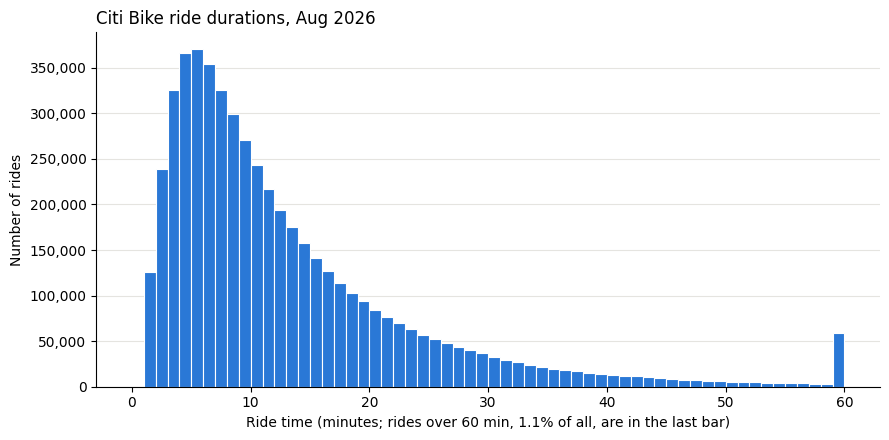

In [ ]:
cutoff = 60  # minutes; the long tail (up to ~24 h) would squash the plot
share_over = (df["ride_time"] > cutoff).mean()
median = df["ride_time"].median()

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(df["ride_time"].clip(upper=cutoff), bins=np.arange(0, cutoff + 1, 1),
        color="#2a78d6", edgecolor="white", linewidth=0.8)

# ax.axvline(median, color="#52514e", linestyle="--", linewidth=1)
# ax.text(median + 0.8, ax.get_ylim()[1] * 0.92, f"median {median:.1f} min", color="#52514e")

ax.set_title("Citi Bike ride durations, Aug 2026", loc="left")
ax.set_xlabel(f"Ride time (minutes; rides over {cutoff} min, {share_over:.1%} of all, are in the last bar)")
ax.set_ylabel("Number of rides")
ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", color="#e5e4e0", linewidth=0.8)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()

### Question 2

To calculate the expected ride duration and empirical variance, we simply find the average and variance of the entire ride_time column in the dataframe:

In [ ]:
# calculating the average ride time and variance of ride time
average_ride_time = df['ride_time'].mean()
var_ride_time = df['ride_time'].var()
print(f"Expected ride duration: {average_ride_time:.2f} min")
print(f"Variance of ride time: {var_ride_time:.2f} min^2 (std dev {var_ride_time**0.5:.2f} min)")

Expected ride duration: 13.40 min
Variance of ride time: 157.14 min^2 (std dev 12.54 min)


To calculate the probability of a ride lasting longer than 20 minutes, we count how many rides lasted longer than 20 minutes and then divide by the number of rides taking by members (Bayes Rule):

In [17]:
# Empirical probability: fraction of rides longer than 20 minutes
p_over_20 = (df["ride_time"] > 20).mean()
print(f"P(ride > 20 min) = {p_over_20:.4f}")

P(ride > 20 min) = 0.1879


### Question 3

We can calculate the conditional probability by filtering the dataset for rides lasting longer than 20 minutes and taken by Citi Bike members and dividing by the total number of rides. This is simply Bayes Rule:

In [1]:
p_joint = ((df["member_casual"] == "member") & (df["ride_time"] > 20)).mean()  # P(A and B)
p_member = (df["member_casual"] == "member").mean()                            # P(B)
print(f"P(): {p_joint / p_member:.4f}")

NameError: name 'df' is not defined

### Question 4

Again, we use Bayes Rule to calculate the conditional probability:

In [24]:
p_joint = ((df["member_casual"] == "member") & (df["ride_time"] > 25)).mean()  # P(A and B)
p_ride_25_min = (df["ride_time"] > 25).mean()                                  # P(B)
print(f"P(member | ride > 25 min) = {p_joint / p_ride_25_min:.4f}")

P(member | ride > 25 min) = 0.6029


### Question 5

In [33]:
# calculating the average ride time of electric bike and average ride time of classic bike
electric_average_ride_time= df.loc[df["rideable_type"] == "electric_bike", "ride_time"].mean()
classic_average_ride_time= df.loc[df["rideable_type"] == "classic_bike", "ride_time"].mean()
print(f"Expected electric bike ride time: {electric_average_ride_time:.2f} min")
print(f"Expected classic bike ride time: {classic_average_ride_time:.2f} min")

Expected electric bike ride time: 13.36 min
Expected classic bike ride time: 13.53 min


### Question 6

In [ ]:
# calculating the probability that a ride uses an electric bike given that the ride time < 10 mins
p_joint = ((df["rideable_type"] == "electric_bike") & (df["ride_time"] < 10)).mean()  # P(A and B)
p_ride_less_than_10 = ((df["ride_time"] < 10)).mean()  # P(B)
print(f"P(Electric Bike | Ride < 10) = {p_joint/p_ride_less_than_10:.2f}")

# calculating the probability that a ride uses an classic bike given that the ride time < 10 mins
p_joint = ((df["rideable_type"] == "classic_bike") & (df["ride_time"] < 10)).mean()  # P(A and B)
p_ride_less_than_10 = ((df["ride_time"] < 10)).mean()  # P(B)
print(f"P(Classic Bike | Ride < 10) = {p_joint/p_ride_less_than_10:.2f}")

p_electric = (df["rideable_type"] == "electric_bike").mean()
print(f"P(Electric Bike) overall = {p_electric:.2f}")


P(Electric Bike | Ride < 10) = 0.72
P(Classic Bike | Ride < 10) = 0.28
P(Electric Bike) overall = 0.73


About 72% of rides under 10 minutes use electric bikes and 28% use classic bikes. However, this closely matches the fact that about 73% of all rides are on electric bikes. Since $P(\text{Electric} \mid \text{Ride} < 10) \approx P(\text{Electric})$, knowing that a ride lasted less than 10 minutes tells us very little about the type of bike used. This is consistent with Question 5, where the average ride times of classic and electric bikes were nearly identical.